# Assignment 63 — Week 7, Day 4
## Topic: Deep Learning — Convolutional Neural Networks

**Objective:** Demonstrate a Convolutional Neural Network (CNN).

**Reference:** https://towardsdatascience.com/a-comprehensive-guide-to-convolutional-neural-networks-the-eli5-way-3bd2b1164a53

A **Convolutional Neural Network (CNN)** is a deep learning model designed for images. Instead of looking at every pixel separately, it slides small **filters (kernels)** over the image to detect local patterns such as edges, then combines them into larger shapes. Following the "ELI5" guide in Towards Data Science, the building blocks are:

- **Input image** – a grid of pixel values (one channel for greyscale, three for RGB).
- **Convolution layer** – kernels slide over the image and produce **feature maps**; **stride** and **padding** control the output size.
- **Pooling layer** – reduces each feature map (max or average pooling), keeping the important information.
- **Fully connected layer** – flattens the features and classifies them with softmax.

This notebook first performs convolution and pooling by hand with NumPy, then builds and trains a CNN with Keras on the MNIST handwritten digits (downloaded automatically by Keras, about 11 MB).

**Diagram:** Convolution and pooling layers learn features; the dense layer at the end classifies them.

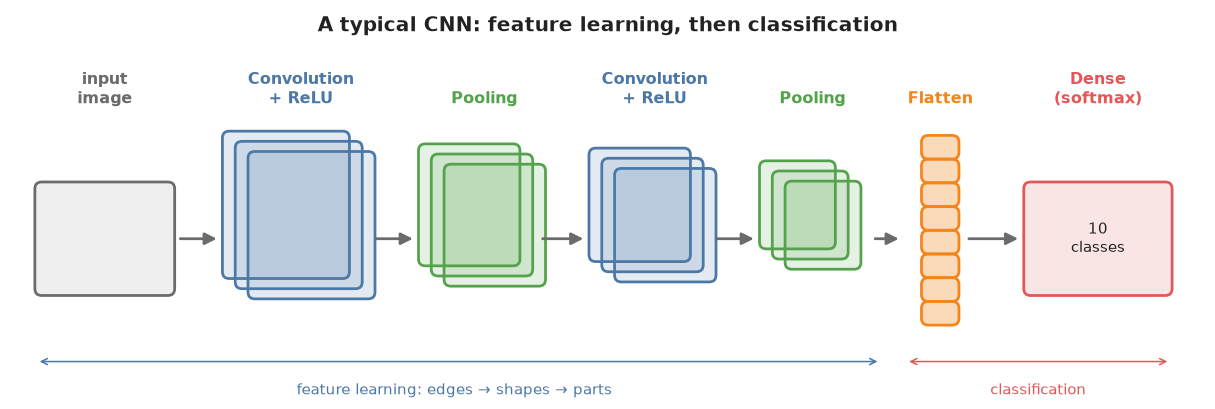

**Set up TensorFlow and Keras**

In [1]:
import os
import logging

# Hide TensorFlow's start-up log messages so the outputs stay readable
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
logging.getLogger("tensorflow").setLevel(logging.ERROR)

import numpy as np
import tensorflow as tf
from tensorflow import keras

tf.get_logger().setLevel(logging.ERROR)
keras.utils.set_random_seed(42)  # makes the results repeatable
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


**Explanation:** The setup cell imports NumPy, TensorFlow and Keras, hides TensorFlow's log messages and fixes the random seed.

**An image is a grid of numbers**

Training images: (60000, 28, 28) | test images: (10000, 28, 28)


Label: 5 | pixel range: 0 to 255
[[  0   0  30  36  94 154 170 253 253 253]
 [  0  49 238 253 253 253 253 253 253 253]
 [  0  18 219 253 253 253 253 253 198 182]
 [  0   0  80 156 107 253 253 205  11   0]
 [  0   0   0  14   1 154 253  90   0   0]
 [  0   0   0   0   0 139 253 190   2   0]]


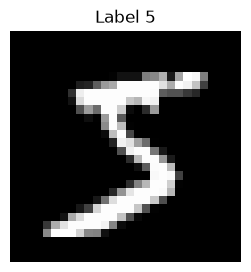

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras

(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()
print("Training images:", x_train.shape, "| test images:", x_test.shape)

image = x_train[0]
print("Label:", y_train[0], "| pixel range:", image.min(), "to", image.max())
print(image[6:12, 6:16])

plt.figure(figsize=(3, 3))
plt.imshow(image, cmap="gray")
plt.title(f"Label {y_train[0]}")
plt.axis("off")
plt.show()

**Explanation:** Each MNIST image is a 28 × 28 grid of greyscale pixel values from 0 (black) to 255 (white). The printed patch shows the numbers behind part of the digit. A colour image would have 3 such grids (red, green and blue channels).

## Convolution by hand

**Diagram:** How one value of a feature map is calculated.

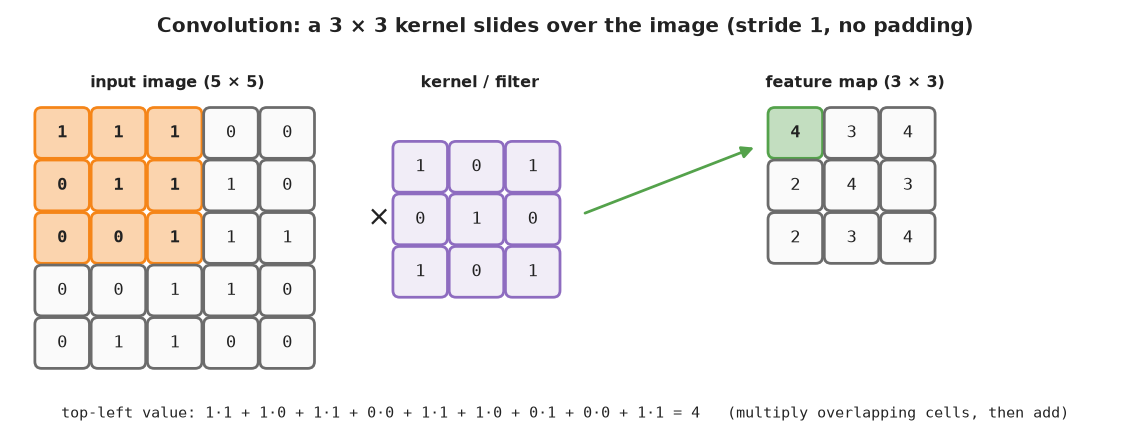

**Convolve a small image with a kernel**

In [3]:
import numpy as np

image = np.array([[1, 1, 1, 0, 0],
                  [0, 1, 1, 1, 0],
                  [0, 0, 1, 1, 1],
                  [0, 0, 1, 1, 0],
                  [0, 1, 1, 0, 0]])

kernel = np.array([[1, 0, 1],
                   [0, 1, 0],
                   [1, 0, 1]])

def convolve2d(img, k, stride=1):
    kh, kw = k.shape
    out_h = (img.shape[0] - kh) // stride + 1
    out_w = (img.shape[1] - kw) // stride + 1
    out = np.zeros((out_h, out_w))
    for r in range(out_h):
        for c in range(out_w):
            patch = img[r * stride:r * stride + kh, c * stride:c * stride + kw]
            out[r, c] = np.sum(patch * k)
    return out

print(convolve2d(image, kernel))

[[4. 3. 4.]
 [2. 4. 3.]
 [2. 3. 4.]]


**Explanation:** This is the ELI5 guide's example: a 5 × 5 image and a 3 × 3 kernel. At each position the overlapping values are multiplied and added, giving a 3 × 3 feature map. With 'valid' padding (no padding) the output is smaller than the input.

**Stride and padding**

In [4]:
import numpy as np

image = np.arange(1, 50).reshape(7, 7)
kernel = np.ones((3, 3)) / 9

def convolve2d(img, k, stride=1):
    kh, kw = k.shape
    out_h = (img.shape[0] - kh) // stride + 1
    out_w = (img.shape[1] - kw) // stride + 1
    return np.array([[np.sum(img[r*stride:r*stride+kh, c*stride:c*stride+kw] * k) for c in range(out_w)]
                     for r in range(out_h)])

print("valid, stride 1:", convolve2d(image, kernel).shape)
print("valid, stride 2:", convolve2d(image, kernel, stride=2).shape)
padded = np.pad(image, 1)
print("same padding, stride 1:", convolve2d(padded, kernel).shape)

valid, stride 1: (5, 5)
valid, stride 2: (3, 3)
same padding, stride 1: (7, 7)


**Explanation:** Stride is how far the kernel moves each step: a stride of 2 roughly halves the output size (5 × 5 becomes 3 × 3 here). 'Same' padding adds a border of zeros so the output keeps the input's size; 'valid' padding uses no border, so the output shrinks.

**Edge-detecting kernels on a real digit**

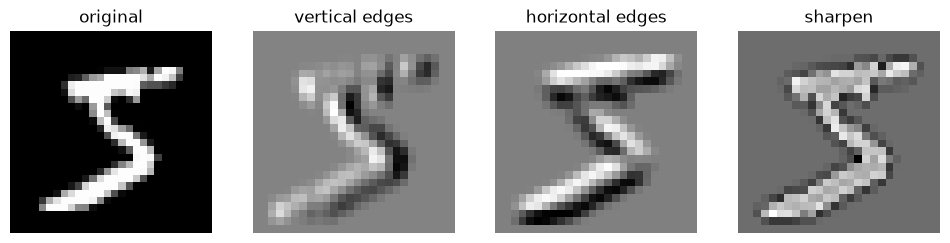

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras

(x_train, y_train), _ = keras.datasets.mnist.load_data()
image = x_train[0].astype("float32") / 255

kernels = {
    "vertical edges": np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]]),
    "horizontal edges": np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]]),
    "sharpen": np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]]),
}

def convolve2d(img, k):
    out = np.zeros((img.shape[0] - 2, img.shape[1] - 2))
    for r in range(out.shape[0]):
        for c in range(out.shape[1]):
            out[r, c] = np.sum(img[r:r + 3, c:c + 3] * k)
    return out

fig, axes = plt.subplots(1, 4, figsize=(12, 3))
axes[0].imshow(image, cmap="gray"); axes[0].set_title("original")
for ax, (name, k) in zip(axes[1:], kernels.items()):
    ax.imshow(convolve2d(image, k), cmap="gray")
    ax.set_title(name)
for ax in axes:
    ax.axis("off")
plt.show()

**Explanation:** Different kernels highlight different features: one responds to vertical edges, another to horizontal edges. A CNN learns its own kernels during training instead of using hand-made ones like these.

## Pooling by hand

**Diagram:** Each colour is one 2 × 2 region and the single value it becomes.

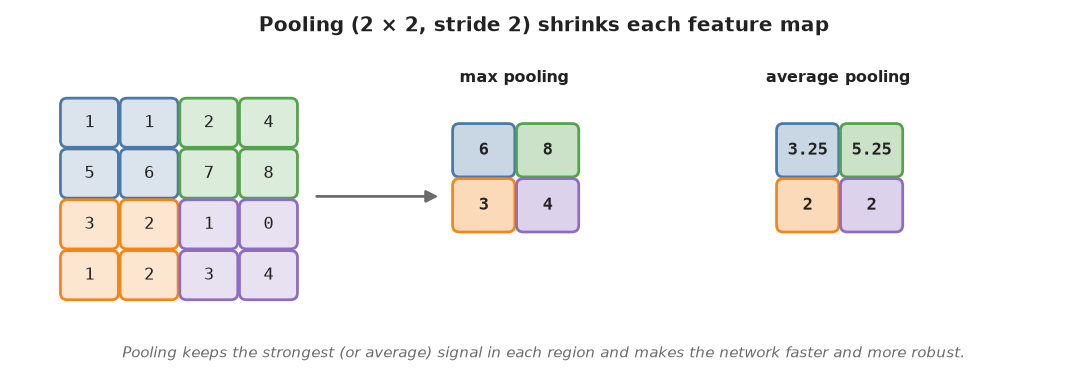

**Max pooling and average pooling**

In [6]:
import numpy as np

feature_map = np.array([[1, 1, 2, 4],
                        [5, 6, 7, 8],
                        [3, 2, 1, 0],
                        [1, 2, 3, 4]])

def pool(x, size=2, mode="max"):
    h, w = x.shape[0] // size, x.shape[1] // size
    blocks = x[:h * size, :w * size].reshape(h, size, w, size)
    return blocks.max(axis=(1, 3)) if mode == "max" else blocks.mean(axis=(1, 3))

print("Max pooling:\n", pool(feature_map, mode="max"))
print("Average pooling:\n", pool(feature_map, mode="avg"))

Max pooling:
 [[6 8]
 [3 4]]
Average pooling:
 [[3.25 5.25]
 [2.   2.  ]]


**Explanation:** Pooling splits the feature map into 2 × 2 regions and keeps one value per region: the largest (max pooling) or the mean (average pooling). The map shrinks from 4 × 4 to 2 × 2. Max pooling is the most common because it also suppresses noise.

## A CNN with Keras

**Prepare the MNIST data**

In [7]:
from tensorflow import keras

(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

x_train = x_train.reshape(-1, 28, 28, 1).astype("float32") / 255
x_test = x_test.reshape(-1, 28, 28, 1).astype("float32") / 255

print(x_train.shape, x_test.shape)

(60000, 28, 28, 1) (10000, 28, 28, 1)


**Explanation:** Pixel values are scaled to 0–1, and a channel dimension is added because Conv2D layers expect images shaped (height, width, channels).

**Build the CNN**

In [8]:
from tensorflow import keras
from tensorflow.keras import layers

model = keras.Sequential([
    keras.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, kernel_size=(3, 3), activation="relu"),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Conv2D(64, kernel_size=(3, 3), activation="relu"),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Flatten(),
    layers.Dropout(0.5),
    layers.Dense(10, activation="softmax"),
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        16,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 34,826 (136.04 KB)

 Trainable params: 34,826 (136.04 KB)

 Non-trainable params: 0 (0.00 B)

**Explanation:** Two convolution + max-pooling blocks learn features; Flatten turns the final feature maps into a vector; Dropout randomly switches off half the connections during training to reduce overfitting; the softmax layer outputs a probability for each of the 10 digits. The summary shows how each layer changes the shape, for example 28 × 28 → 26 × 26 × 32 after the first convolution.

**Train and evaluate the CNN**

In [9]:
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(42)
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()
x_train = x_train.reshape(-1, 28, 28, 1).astype("float32") / 255
x_test = x_test.reshape(-1, 28, 28, 1).astype("float32") / 255

model = keras.Sequential([
    keras.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation="relu"), layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"), layers.MaxPooling2D((2, 2)),
    layers.Flatten(), layers.Dropout(0.5), layers.Dense(10, activation="softmax"),
])
model.compile(loss="sparse_categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

history = model.fit(x_train, y_train, batch_size=128, epochs=3, validation_split=0.1, verbose=2)

test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"Test accuracy: {test_acc:.4f}")
model.save("mnist_cnn.keras")

Epoch 1/3


422/422 - 14s - 34ms/step - accuracy: 0.8927 - loss: 0.3584 - val_accuracy: 0.9778 - val_loss: 0.0805


Epoch 2/3


422/422 - 14s - 33ms/step - accuracy: 0.9660 - loss: 0.1097 - val_accuracy: 0.9833 - val_loss: 0.0579


Epoch 3/3


422/422 - 14s - 33ms/step - accuracy: 0.9741 - loss: 0.0849 - val_accuracy: 0.9877 - val_loss: 0.0459


Test accuracy: 0.9852


**Explanation:** The model is trained for 3 epochs, which takes a minute or two on a CPU. Even this small CNN recognises about 98.5% of the test digits. The trained model is saved so the next cells can use it without retraining.

**What the first convolution layer sees**

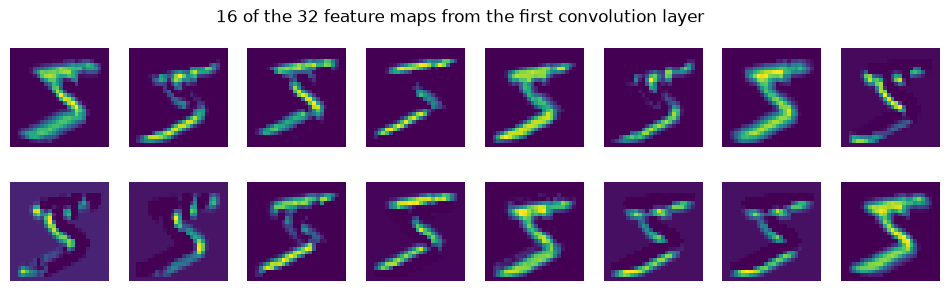

In [10]:
import matplotlib.pyplot as plt
from tensorflow import keras

model = keras.models.load_model("mnist_cnn.keras")
(x_train, _), _ = keras.datasets.mnist.load_data()
image = x_train[0].reshape(1, 28, 28, 1).astype("float32") / 255

first_conv = keras.Model(inputs=model.inputs, outputs=model.layers[0].output)
feature_maps = first_conv.predict(image, verbose=0)[0]

fig, axes = plt.subplots(2, 8, figsize=(12, 3.2))
for i, ax in enumerate(axes.flat):
    ax.imshow(feature_maps[:, :, i], cmap="viridis")
    ax.axis("off")
plt.suptitle("16 of the 32 feature maps from the first convolution layer")
plt.show()

**Explanation:** Each feature map is the output of one learned kernel. Some light up on vertical strokes, others on horizontal strokes or curves, just like the hand-made edge kernels above, but learned automatically from the data.

**Predictions on test images**

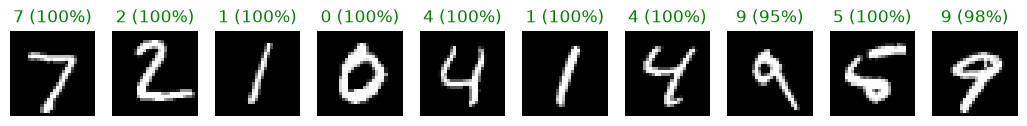

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras

model = keras.models.load_model("mnist_cnn.keras")
_, (x_test, y_test) = keras.datasets.mnist.load_data()
images = x_test[:10].reshape(-1, 28, 28, 1).astype("float32") / 255

probabilities = model.predict(images, verbose=0)
predictions = probabilities.argmax(axis=1)

fig, axes = plt.subplots(1, 10, figsize=(13, 2))
for ax, img, pred, true, p in zip(axes, x_test[:10], predictions, y_test[:10], probabilities.max(axis=1)):
    ax.imshow(img, cmap="gray")
    ax.set_title(f"{pred} ({p:.0%})", color="green" if pred == true else "red")
    ax.axis("off")
plt.show()

**Explanation:** Each title shows the predicted digit and the model's confidence. Green means the prediction matches the true label.

## Observation

- An image is a grid of pixel values; a CNN processes it with small kernels instead of treating every pixel independently.
- Convolution multiplies a kernel with each image patch and sums the result, producing a feature map; stride and padding control its size.
- Pooling shrinks feature maps by keeping the maximum or average of each region.
- Early layers detect simple features such as edges; deeper layers combine them into shapes.
- A small Keras CNN (two convolution and pooling blocks, then a dense softmax layer) recognises about 98.5% of MNIST test digits after only 3 epochs.

## Conclusion

CNNs learn their own image filters, so they extract useful features automatically and need far fewer weights than a fully connected network on raw pixels. This makes them the standard architecture for image recognition.